# Three-sensor pixel opportunity: Aqua, NOAA-20, NOAA-21

This notebook extends the exact July 6, 2025 Q3 candidate neighborhood to three source swaths and three observed FIRMS coordinates. It verifies both geolocation download manifests, verifies the selected L2 source files exist, performs nearest-center lookups on all nine coordinate/swath combinations, and samples each native L2 fire mask at its matching geolocation index. VIIRS coordinate arrays are streamed in chunks.

These sample rows were selected from a candidate-linked stratum. This is a case study, not an independent accuracy sample. Overpass times differ by up to 129 minutes; mask differences cannot by themselves demonstrate a sensor miss or continuous fire activity.

In [1]:
from pathlib import Path
import sys, json, hashlib
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from IPython.display import display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'data/reference').is_dir())
sys.path.insert(0, str(ROOT))
from src.firewatch.coverage_validation import paired_modis_point, paired_viirs_point, sha256_file
plan2_path = ROOT / 'data/reference/geolocation_coverage_plan_2025.csv'
plan20_path = ROOT / 'data/reference/geolocation_coverage_plan_2025_noaa20.csv'
geo2_dir = ROOT / 'data/reference/granules/geolocation_pilot'
geo20_dir = ROOT / 'data/reference/granules/geolocation_noaa20_pilot'
l2_dir = ROOT / 'data/reference/granules/validation_2025'
plan2, plan20 = pd.read_csv(plan2_path), pd.read_csv(plan20_path)
for plan_path, folder, expected_count in [(plan2_path,geo2_dir,2),(plan20_path,geo20_dir,1)]:
    manifest = json.loads((folder/'download_manifest.json').read_text(encoding='utf-8'))
    assert manifest['plan_sha256'] == hashlib.sha256(plan_path.read_bytes()).hexdigest()
    assert manifest['download_count'] == expected_count
    for rec in manifest['downloads']:
        staged = folder/rec['filename']
        assert staged.is_file() and staged.stat().st_size == rec['bytes']
        assert sha256_file(staged) == rec['sha256']
print('All three geolocation files match their plan-linked SHA-256 manifests.')

All three geolocation files match their plan-linked SHA-256 manifests.


In [2]:
sample = pd.read_csv(ROOT/'data/processed/source_pixel_validation_2025_stratified.csv')
q3 = sample[(sample.quarter=='Q3') & sample.candidate_status & sample.candidate_status_label.eq('has_candidate_link')]
records = {sat: q3[q3.satellite.eq(sat)].iloc[0] for sat in ['Aqua','N20','N21']}
points = {sat: (float(r.csv_latitude),float(r.csv_longitude)) for sat,r in records.items()}
l2_paths = {sat:l2_dir/r.granule_id for sat,r in records.items()}
for sat,p in l2_paths.items(): assert p.is_file(), f'Missing {sat} L2 source file: {p}'
geo_paths = {
    'Aqua': geo2_dir/plan2.loc[plan2.satellite.eq('Aqua'),'geolocation_granule_id'].iloc[0],
    'N21': geo2_dir/plan2.loc[plan2.satellite.eq('N21'),'geolocation_granule_id'].iloc[0],
    'N20': geo20_dir/plan20.iloc[0].geolocation_granule_id,
}
display(pd.DataFrame([{'satellite':s,'time_utc':r.observation_time_utc,'latitude':points[s][0],'longitude':points[s][1],'L2_granule':r.granule_id,'geolocation_granule':geo_paths[s].name} for s,r in records.items()]))

,satellite,time_utc,latitude,longitude,L2_granule,geolocation_granule
0,Aqua,2025-07-06T13:48:00+00:00,11.83500,14.99200,MYD14.A2025187.1345.061.2025188110859.hdf,MYD03.A2025187.1345.061.2025188145533.hdf
1,N20,2025-07-06T11:39:00+00:00,11.84300,14.99202,VJ114IMG.A2025187.1136.002.2025187162721.nc,VJ103IMG.A2025187.1136.021.2025187154117.nc
2,N21,2025-07-06T12:30:00+00:00,11.83285,14.99122,VJ214IMG.A2025187.1230.002.2025327203213.nc,VJ203IMG.A2025187.1230.021.2025187181751.nc


In [3]:
readers = {'Aqua':paired_modis_point,'N20':paired_viirs_point,'N21':paired_viirs_point}
rows=[]
for target_sat,target in points.items():
    lat,lon=target
    for swath in ['Aqua','N20','N21']:
        result=readers[swath](geo_paths[swath],l2_paths[swath],lat,lon)
        rows.append({'target_observation':target_sat,'queried_swath':swath,'target_time_utc':records[target_sat].observation_time_utc,**result})
coverage=pd.DataFrame(rows)
coverage.to_csv(ROOT/'data/processed/three_sensor_pixel_opportunity_2025_pilot.csv',index=False)
display(coverage[['target_observation','queried_swath','distance_km','fire_mask_class','fire_mask_label','gflags','quality_flag','quality_flag_usable']])
print('Saved data/processed/three_sensor_pixel_opportunity_2025_pilot.csv')

,target_observation,queried_swath,distance_km,fire_mask_class,fire_mask_label,gflags,quality_flag,quality_flag_usable
0,Aqua,Aqua,0.001617,8,fire_nominal_confidence,0.0,NaN,NaN
1,Aqua,N20,0.144561,5,clear_land,NaN,0.0,True
2,Aqua,N21,0.215145,5,clear_land,NaN,0.0,True
3,N20,Aqua,0.219229,5,clear_land,0.0,NaN,NaN
4,N20,N20,0.000482,8,fire_nominal_confidence,NaN,0.0,True
5,N20,N21,0.241144,8,fire_nominal_confidence,NaN,0.0,True
6,N21,Aqua,0.253241,8,fire_nominal_confidence,0.0,NaN,NaN
7,N21,N20,0.154342,1,bowtie,NaN,0.0,True
8,N21,N21,0.000165,8,fire_nominal_confidence,NaN,0.0,True


Saved data/processed/three_sensor_pixel_opportunity_2025_pilot.csv


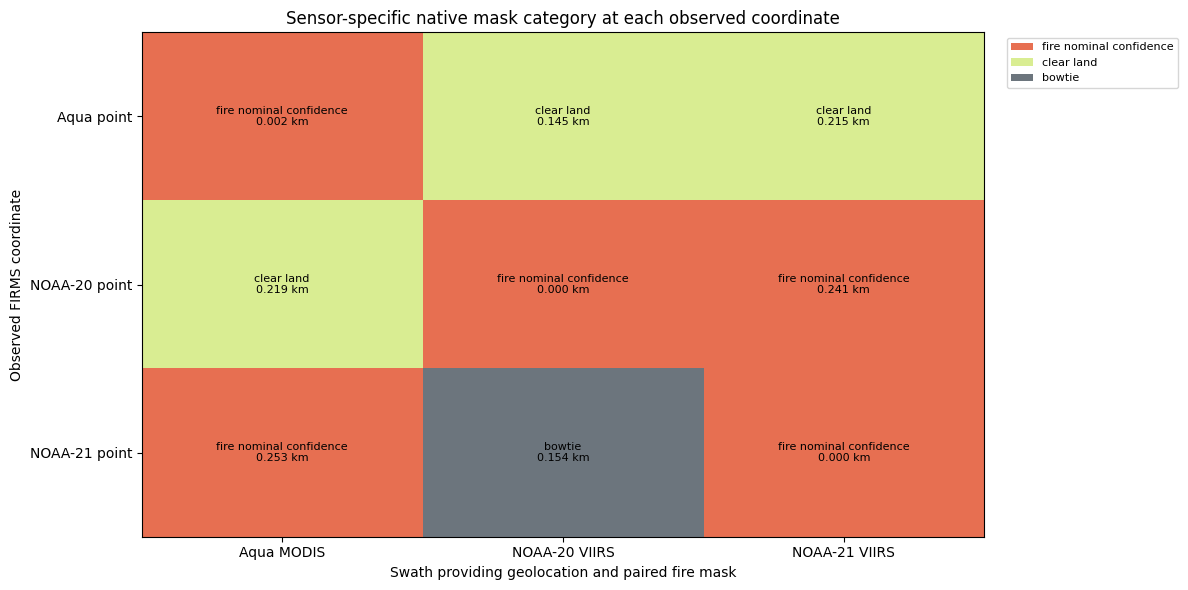

In [4]:
# Sensor-specific mask labels differ (for example, VIIRS class 1 is bowtie).
# Plot semantic labels rather than a shared numeric class code.
from matplotlib.patches import Patch
matrix = coverage.pivot(index='target_observation', columns='queried_swath', values='fire_mask_label').reindex(
    index=['Aqua','N20','N21'], columns=['Aqua','N20','N21'])
semantic_colors = {
    'missing_input_data':'#777777', 'not_processed_obsolete':'#aaaaaa',
    'not_processed_nonzero_qf':'#777777', 'bowtie':'#6c757d', 'glint':'#9467bd',
    'water':'#247ba0', 'cloud':'#a9def9', 'clear_land':'#d9ed92',
    'unknown':'#f1c0e8', 'unclassified':'#f1c0e8',
    'fire_low_confidence':'#f4a261', 'fire_nominal_confidence':'#e76f51',
    'fire_high_confidence':'#9d0208',
}
labels = list(dict.fromkeys(matrix.to_numpy().ravel()))
label_index = {label:i for i,label in enumerate(labels)}
encoded = matrix.apply(lambda col: col.map(label_index)).to_numpy(dtype=float)
cmap = ListedColormap([semantic_colors.get(label,'#888888') for label in labels])
norm = BoundaryNorm([i-.5 for i in range(len(labels)+1)], len(labels))
fig,ax=plt.subplots(figsize=(12,6))
ax.imshow(encoded,cmap=cmap,norm=norm,aspect='auto')
ax.set_xticks(range(3),['Aqua MODIS','NOAA-20 VIIRS','NOAA-21 VIIRS'])
ax.set_yticks(range(3),['Aqua point','NOAA-20 point','NOAA-21 point'])
for i,target in enumerate(matrix.index):
    for j,swath in enumerate(matrix.columns):
        row=coverage[(coverage.target_observation==target)&(coverage.queried_swath==swath)].iloc[0]
        label=row.fire_mask_label.replace('_',' ')
        ax.text(j,i,f"{label}\n{row.distance_km:.3f} km",ha='center',va='center',fontsize=8)
ax.set_title('Sensor-specific native mask category at each observed coordinate')
ax.set_xlabel('Swath providing geolocation and paired fire mask')
ax.set_ylabel('Observed FIRMS coordinate')
handles=[Patch(facecolor=semantic_colors.get(label,'#888888'),label=label.replace('_',' ')) for label in labels]
ax.legend(handles=handles,bbox_to_anchor=(1.02,1),loc='upper left',fontsize=8)
fig.tight_layout()
plt.show()


## How to interpret this matrix

Each cell is the nearest geolocation pixel center in a swath to one of the three observed coordinates, followed by the paired swath's native fire-mask category. The distance is to the pixel center, not a footprint-overlap distance. VIIRS quality flags and MODIS `gflags` remain in the CSV output for inspection.

Mask classes 3 (water), 4 (cloud), 5 (clear land), 6 (unknown), and 7–9 (fire confidence) have different meanings and must not be collapsed into a binary no-fire class. A nominal fire class at a nearby coordinate in another swath does not prove a same event. Overpass timing, pixel footprint, detection algorithm, and geolocation uncertainty all matter. Broader performance claims require a representative linked/unlinked sample and independent reference data.